# Topic discovery from original CMV posts

Use one original post per discussion in the archived P4 training cohort. Titles and bodies supply topic information. Available flairs were generally missing or tracked moderation and outcomes. P4's archived discussion IDs define the cohort. Clustering uses OP text alone.

The [discovery script](discover_op_topics.py) uses [all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2) and [BERTopic](https://maartengr.github.io/BERTopic/). Titles and bodies are minimally cleaned, and the body ignores quote lines and marked edit sections. Embed the title separately and split long bodies into model-sized chunks. Pool normalized body chunks by token count, combine the title and body vectors at 40% and 60%, and renormalize. Use the available vector when only one is present.

BERTopic uses seeded UMAP, HDBSCAN with minimum cluster size 40 and minimum samples 10, and class-based TF-IDF keywords. Topic IDs are exploratory cluster identifiers. Keep the HDBSCAN outlier group `-1` visible for review.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "team-setup").is_dir() and (p / "pyproject.toml").is_file()
)
DATA = REPO / "project/data/processed/linguistic-features"
RUNS = DATA / "op-topic-discovery"
RUN_ID = None
runs = sorted(RUNS.glob("*/results.json"))
if RUN_ID is None and not runs:
    raise FileNotFoundError("Run discover_op_topics.py with a locally cached MiniLM model first.")
report_path = RUNS / RUN_ID / "results.json" if RUN_ID else runs[-1]
run = report_path.parent
report = json.loads(report_path.read_text())
assert report["split"] == "train"
assignments = pd.read_parquet(run / "op_topic_assignments.parquet")
assert assignments["post_id"].is_unique and len(assignments) == report["discussions"]
print(f"{len(assignments):,} unique training discussions")
print(f"{report['clusters']} clusters and {report['outliers']:,} outlier discussions ({report['outliers'] / len(assignments):.1%})")

2,507 unique training discussions
25 clusters and 227 outlier discussions (9.1%)


## Blind title review

The seeded 100-title sample contains OP titles and a blank manual label column. Review this file before opening the model's cluster labels. Broad categories can include politics, ethics, technology, culture, relationships, work and economics, and religion. Use **Other / unclear** where a short title or competing themes make a label uncertain.

In [2]:
titles = pd.read_csv(run / "random_title_review.csv", keep_default_na=False)
assert len(titles) == 100 and titles["post_id"].is_unique
print(f"Review all 100 titles in {run / 'random_title_review.csv'}")
display(titles.head(15).set_index("post_id"))

Review all 100 titles in /Users/paolacalle/Desktop/NYU/semesters/fall-2026/ml-viz/ml-visualization-project/ml-visualization-project/project/data/processed/linguistic-features/op-topic-discovery/20261120T221529517368Z/random_title_review.csv


,title,manual_topic
post_id,,
t3_2s8qu4,CMV: Multiculturalism is slowly destroying European cultures,
t3_1bwu2v,I think sterilization should be an optional punishment for those found guilty of child negligence/abuse. CMV,
t3_33yolt,CMV: Art should not be treated as an academic discipline,
t3_26nxhn,"CMV: I believe the word ""nigger"" should be reattributed to a different meaning.",
t3_2d9xj4,"CMV:A person under the effects of Mescaline, LSD or Psilocybin is no less ""in contact"" with reality than a sober person.",
t3_1udlql,"I think its OK to pee in the shower, and should no be discouraged at a young age, CMV.",
t3_1et89u,The Iraq War was both just and necessary. CMV.,
t3_1xti2t,"MLB is concerned that only ~10% of their players are African American. If this is a legitimate concern, I believe the NBA should also be concerned that ~17% of their players are white, CMV",
t3_1z0klq,"I think civilians should be allowed to own explosives, including but not limited to rocket launchers - CMV",


## Cluster coverage and review examples

Review each cluster's keywords, central examples, and random examples before merging clusters. Central examples are closest to the average embedding of assigned posts. Random examples help check whether a proposed label extends beyond the most typical posts. HDBSCAN membership strength is a clustering diagnostic.

,discussions,keywords,Share (%)
topic_id,,,
-1,227,"people, think, dont, like, just, believe, right, feel, cmv, fat, im, rights",9.1
0,224,"vote, people, voting, country, government, think, believe, dont, war, power, just, democracy",8.9
1,210,"money, people, tax, work, income, government, welfare, pay, think, rich, wealth, make",8.4
2,173,"god, religion, religious, believe, people, bible, universe, dont, think, science, belief, human",6.9
3,131,"music, like, movies, just, song, book, books, really, movie, dont, time, read",5.2
4,130,"white, black, racism, people, racist, race, word, culture, american, im, think, like",5.2
5,110,"school, students, college, teachers, education, schools, job, math, learning, time, philosophy, science",4.4
6,106,"rape, sex, believe, crime, raped, consent, victims, dont, victim, crimes, death, people",4.2
7,100,"reddit, people, subreddit, subreddits, posts, comments, like, news, think, views, believe, opinion",4.0


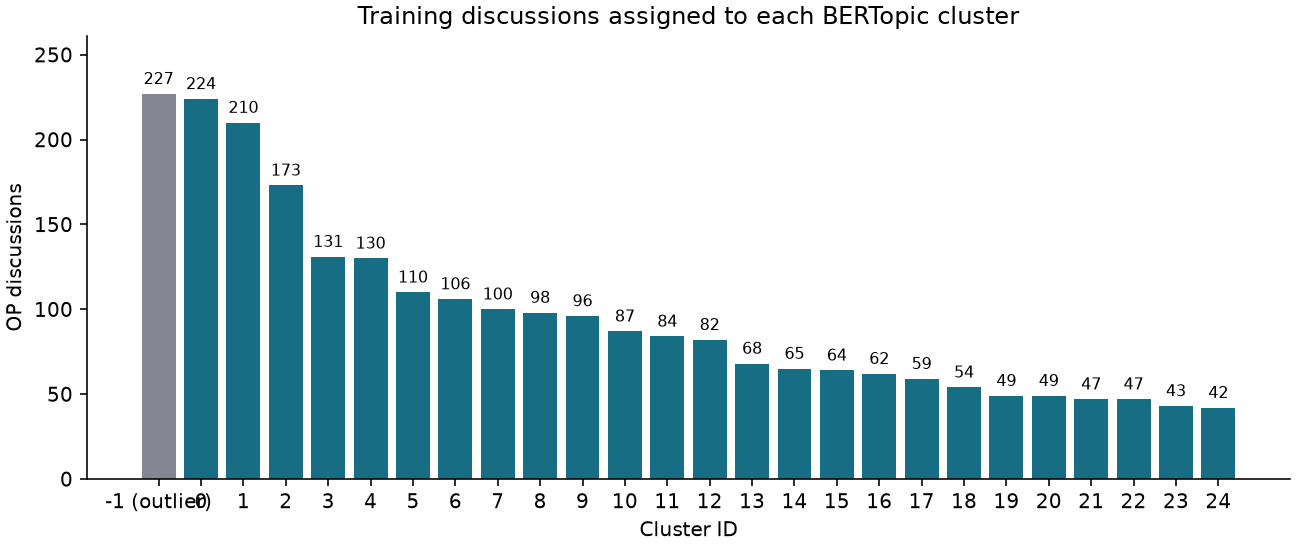

Full representative and random sample: /Users/paolacalle/Desktop/NYU/semesters/fall-2026/ml-viz/ml-visualization-project/ml-visualization-project/project/data/processed/linguistic-features/op-topic-discovery/20261120T221529517368Z/cluster_review.csv


,example_type,title
topic_id,,
-1,Random,"When I see someone who is obese, I immediately think of them as stupid or lazy. CMV"
-1,Random,"CMV: That American society is getting better, not worse"
0,Representative,I believe the average young american has a very very dim future ahead of them CMV
0,Representative,CMV: I feel that the fundamental problem in American politics is a dangerously ill-informed populace
1,Representative,CMV: We should strengthen the traditional safety net rather than replace it with basic income
1,Representative,"CMV: I think basic income is wrong because nobody is ""entitled"" to money just because they exist."
2,Representative,I think belief in God is indefensible on any grounds CMV
2,Representative,CMV: I believe God is a completely illogical concept with no basis in reality and was created solely to help us cope with our mortality.
3,Representative,CMV: Focusing too narrowly on the plot of movies is a shallow way of experiencing and critiquing them


In [3]:
import matplotlib.pyplot as plt

summary = pd.read_csv(run / "cluster_summary.csv", keep_default_na=False).set_index("topic_id")
examples = pd.read_csv(run / "cluster_review.csv", keep_default_na=False)
review = summary.copy()
review["Share (%)"] = 100 * review["discussions"] / len(assignments)
display(review.round(1))

fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
labels = ["-1 (outlier)" if topic == -1 else str(topic) for topic in review.index]
bars = ax.bar(labels, review["discussions"], color=["#858693" if t == -1 else "#176d83" for t in review.index])
ax.set(title="Training discussions assigned to each BERTopic cluster", xlabel="Cluster ID", ylabel="OP discussions")
ax.bar_label(bars, padding=3, fontsize=8)
ax.margins(y=0.15)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print(f"Full representative and random sample: {run / 'cluster_review.csv'}")
display(examples.groupby("topic_id", sort=True).head(2)[["topic_id", "example_type", "title"]].set_index("topic_id"))

## Link clusters to the original P4 pairs

Join by OP discussion ID so both openings share the same cluster. This table checks coverage and sample support for the exploratory groups. It includes outliers. Broad topic labels should be reviewed against the original posts before estimating topic-specific feature effects. The embedding and clustering fit here use the full training corpus for discovery. Predictive P5 evaluation would have to learn its topic pipeline inside each training fold.

In [4]:
p4 = DATA / "paired-models/p2_plus_reply_timing_and_external_link" / report["p4_run"]
p4_report = json.loads((p4 / "results.json").read_text())
assert p4_report["split"] == "train"
pairs = pd.read_parquet(p4 / "oof_predictions.parquet", columns=["pair_id", "post_id"])
pair_topics = pairs.merge(assignments[["post_id", "topic_id"]], on="post_id", how="left", validate="many_to_one")
assert len(pair_topics) == len(pairs) and pair_topics["topic_id"].notna().all()
assert pair_topics["pair_id"].is_unique
pair_coverage = pair_topics.groupby("topic_id").agg(pairs=("pair_id", "size"), discussions=("post_id", "nunique"))
display(pair_coverage)
print(f"Joined {len(pair_topics):,} P4 training pairs.")

,pairs,discussions
topic_id,,
-1,317,227
0,296,224
1,291,210
2,252,173
3,176,131
4,170,130
5,163,110
6,140,106
7,123,100


Joined 3,451 P4 training pairs.


## Draft broad topics and P4 performance

The draft groups were named and merged using keywords and representative and random OP examples before opening P4's scores. The mapping is tied to this discovery run. Several clusters span neighboring themes. For example, the substance-use cluster includes drug policy, and the transport cluster includes regulation. The 100-title review gives us a way to check those choices.

The table uses P4's saved out-of-fold predictions. Bootstrap whole OP discussions within each group for 95% intervals. Treat the breakdown as descriptive: grouping was learned on the full training corpus, the groups differ in composition, and these intervals do not test differences between topics.

In [5]:
from sklearn.metrics import roc_auc_score

mapping_path = (
    REPO / "project/notebooks/linguistic-features/topics" / f"draft_topic_labels_{run.name}.csv"
)
if mapping_path.is_file():
    mapping = pd.read_csv(mapping_path)
    assert set(mapping["topic_id"]) == set(assignments["topic_id"])
    assert mapping["topic_id"].is_unique
    assert mapping.set_index("topic_id").loc[-1, "broad_topic"] == "Other / unclear"

    drafts = pair_topics.merge(mapping, on="topic_id", validate="many_to_one")
    scores = pd.read_parquet(p4 / "oof_predictions.parquet", columns=[
        "pair_id", "a_wins", "oof_probability_a_wins",
    ])
    drafts = drafts.merge(scores, on="pair_id", validate="one_to_one")
    assert len(drafts) == p4_report["pairs"]
    draft_clusters = mapping.set_index("topic_id").join(pair_coverage)
    display(draft_clusters)

    rng = np.random.default_rng(42)
    rows = []
    for label, group in drafts.groupby("broad_topic", sort=True):
        codes, posts = pd.factorize(group["post_id"])
        target = group["a_wins"].to_numpy()
        probability = group["oof_probability_a_wins"].to_numpy()
        correct = (probability >= 0.5) == target
        draws = []
        for _ in range(1000):
            weights = rng.multinomial(len(posts), np.full(len(posts), 1 / len(posts)))[codes]
            if weights[target == 0].any() and weights[target == 1].any():
                draws.append((np.average(correct, weights=weights),
                              roc_auc_score(target, probability, sample_weight=weights)))
        lower, upper = np.quantile(draws, [0.025, 0.975], axis=0)
        rows.append({
            "Topic": label, "Pairs": len(group), "OP discussions": len(posts),
            "Accuracy (95% CI)": f"{correct.mean():.1%} [{lower[0]:.1%}, {upper[0]:.1%}]",
            "ROC-AUC (95% CI)": f"{roc_auc_score(target, probability):.3f} [{lower[1]:.3f}, {upper[1]:.3f}]",
        })
    display(pd.DataFrame(rows).set_index("Topic").sort_values("Pairs", ascending=False))
else:
    print("Draft labels are pending review for this discovery run.")

,broad_topic,cluster_label,pairs,discussions
topic_id,,,,
-1,Other / unclear,HDBSCAN outliers,317,227
0,Politics & law,Government and elections,296,224
1,"Education, work & economics",Taxation and social spending,291,210
2,Ethics & religion,God and the meaning of life,252,173
3,"Media, leisure & everyday life",Film and popular culture,176,131
4,Identity & relationships,Race and racism,170,130
5,"Education, work & economics",Schools and higher education,163,110
6,Politics & law,Criminal justice and punishment,140,106
7,"Media, leisure & everyday life",Reddit and online communities,123,100


,Pairs,OP discussions,Accuracy (95% CI),ROC-AUC (95% CI)
Topic,,,,
Identity & relationships,650,484,"66.3% [62.7%, 69.9%]","0.727 [0.686, 0.764]"
"Media, leisure & everyday life",554,412,"66.6% [62.5%, 70.3%]","0.725 [0.680, 0.769]"
Politics & law,518,392,"65.1% [60.6%, 69.8%]","0.712 [0.664, 0.756]"
"Education, work & economics",454,320,"65.6% [61.0%, 70.4%]","0.727 [0.679, 0.777]"
Ethics & religion,454,323,"70.5% [65.9%, 75.0%]","0.766 [0.719, 0.811]"
Other / unclear,317,227,"68.5% [62.9%, 73.5%]","0.741 [0.683, 0.794]"
Technology & environment,285,199,"64.2% [57.9%, 70.8%]","0.717 [0.650, 0.783]"
Health & reproduction,219,150,"67.6% [60.8%, 73.9%]","0.741 [0.668, 0.808]"


## Manual title labels against the draft clusters

This comparison uses the 100 labels supplied in the pasted table, aligned to the original seeded title order. The manual and draft taxonomies group topics differently. The contingency table shows where the two schemes line up or split. The most common manual label in a draft group is descriptive and is estimated from this same sample.

The manual review uses titles. The model also uses OP bodies, so disagreement can reflect missing title context as well as cluster composition or category boundaries. BERTopic's outlier designation indicates weak cluster membership. A title in that group can still have a clear manual category.

In [6]:
manual_path = run / "manual_title_topics.csv"
if manual_path.is_file():
    manual = pd.read_csv(manual_path, keep_default_na=False)
    pd.testing.assert_frame_equal(manual[["post_id", "title"]], titles[["post_id", "title"]])
    assert manual["manual_topic"].str.strip().ne("").all()
    manual_review = manual.merge(
        assignments[["post_id", "topic_id"]], on="post_id", validate="one_to_one",
    ).merge(mapping, on="topic_id", validate="many_to_one")
    assert len(manual_review) == len(manual)
    counts = pd.crosstab(manual_review["broad_topic"], manual_review["manual_topic"])
    display(pd.crosstab(manual_review["broad_topic"], manual_review["manual_topic"], margins=True))

    support = counts.sum(axis=1)
    majority = counts.max(axis=1)
    display(pd.DataFrame({
        "Titles reviewed": support,
        "Most common manual label": counts.idxmax(axis=1),
        "Titles with that label": majority,
        "Share (%)": (100 * majority / support).round(1),
    }).sort_values("Titles reviewed", ascending=False))

    by_cluster = pd.crosstab(manual_review["topic_id"], manual_review["manual_topic"])
    display(mapping.set_index("topic_id")[["cluster_label"]].join(by_cluster, how="right"))
else:
    print("Manual review labels are pending for this discovery run.")

manual_topic,"Arts, Media & Sports",Education & Work,Ethics & Religion,Other / Unclear,Politics & Law,Science & Health,Society & Identity,Technology & Economics,All
broad_topic,,,,,,,,,
"Education, work & economics",0,9,2,0,4,0,0,2,17
Ethics & religion,0,0,11,0,0,2,0,0,13
Health & reproduction,0,0,1,0,0,4,0,0,5
Identity & relationships,0,1,2,0,0,3,10,1,17
"Media, leisure & everyday life",10,3,1,1,1,0,2,2,20
Other / unclear,0,0,1,0,1,1,2,0,5
Politics & law,0,0,2,0,9,0,3,0,14
Technology & environment,2,0,0,0,2,1,0,4,9
All,12,13,20,1,17,11,17,9,100


,Titles reviewed,Most common manual label,Titles with that label,Share (%)
broad_topic,,,,
"Media, leisure & everyday life",20,"Arts, Media & Sports",10,50.0
"Education, work & economics",17,Education & Work,9,52.9
Identity & relationships,17,Society & Identity,10,58.8
Politics & law,14,Politics & Law,9,64.3
Ethics & religion,13,Ethics & Religion,11,84.6
Technology & environment,9,Technology & Economics,4,44.4
Health & reproduction,5,Science & Health,4,80.0
Other / unclear,5,Society & Identity,2,40.0


,cluster_label,"Arts, Media & Sports",Education & Work,Ethics & Religion,Other / Unclear,Politics & Law,Science & Health,Society & Identity,Technology & Economics
topic_id,,,,,,,,,
-1,HDBSCAN outliers,0,0,1,0,1,1,2,0
0,Government and elections,0,0,2,0,6,0,0,0
1,Taxation and social spending,0,4,2,0,4,0,0,2
2,God and the meaning of life,0,0,5,0,0,1,0,0
3,Film and popular culture,7,0,0,0,0,0,0,0
4,Race and racism,0,1,0,0,0,0,4,0
5,Schools and higher education,0,5,0,0,0,0,0,0
6,Criminal justice and punishment,0,0,0,0,1,0,3,0
7,Reddit and online communities,0,0,1,1,1,0,1,0
